# Phase 4 — descriptive comparisons and missingness sensitivity

Same accepted historical cohort as Notebook 02. These are observed-record comparisons, not population/causal tests. No p-values, confidence intervals or salary statistics are generated.

## 1. Revalidate and recompute
This notebook independently reruns the SQL/pandas reconciliation rather than trusting cached notebook outputs.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
from IPython.display import display, Image, Markdown

ROOT = Path.cwd()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'config/phase3_rules.json').exists(), 'Run inside the project.'
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print('Python:', sys.version.split()[0])

Python: 3.12.7


In [2]:
from src.analysis import verified_connection, compute_tables, reconcile, descriptive_comparisons
with verified_connection(ROOT) as (connection, phase3, database_hash):
    tables=compute_tables(connection,ROOT)
    checked=reconcile(connection,ROOT,tables)
assert all(item['status']=='matched' for item in checked.values())
display(pd.DataFrame(checked).T)

,status,rows,columns
cohort_audit,matched,4,3
role_summary,matched,4,16
skill_by_role,matched,780,10
geography_by_role,matched,243,10
county_by_role,matched,32,4
geography_coverage,matched,1,7
seniority_by_role,matched,23,5
locality_skill_by_role,matched,5495,11
skill_count_summary,matched,4,8


## 2. Tag-count distributions
Use only populated lists. Mean, median and IQR describe publisher tag-list length, not job complexity. SQL interpolates quantiles at (n−1)q and pandas independently checks them. Box whiskers are observed min/max, not 1.5×IQR.

,role,usable_tag_records,mean_tags,min_tags,max_tags,q1_tags,median_tags,q3_tags,iqr_tags
0,Data Analyst,4093,4.182995,1,18,2.0,4.0,5.0,3.0
1,Data Engineer,1928,7.051867,1,24,4.0,7.0,9.0,5.0
2,Data Scientist,5019,5.314206,1,24,3.0,5.0,7.0,4.0
3,Machine Learning Engineer,61,5.901639,1,14,3.0,5.0,7.0,4.0


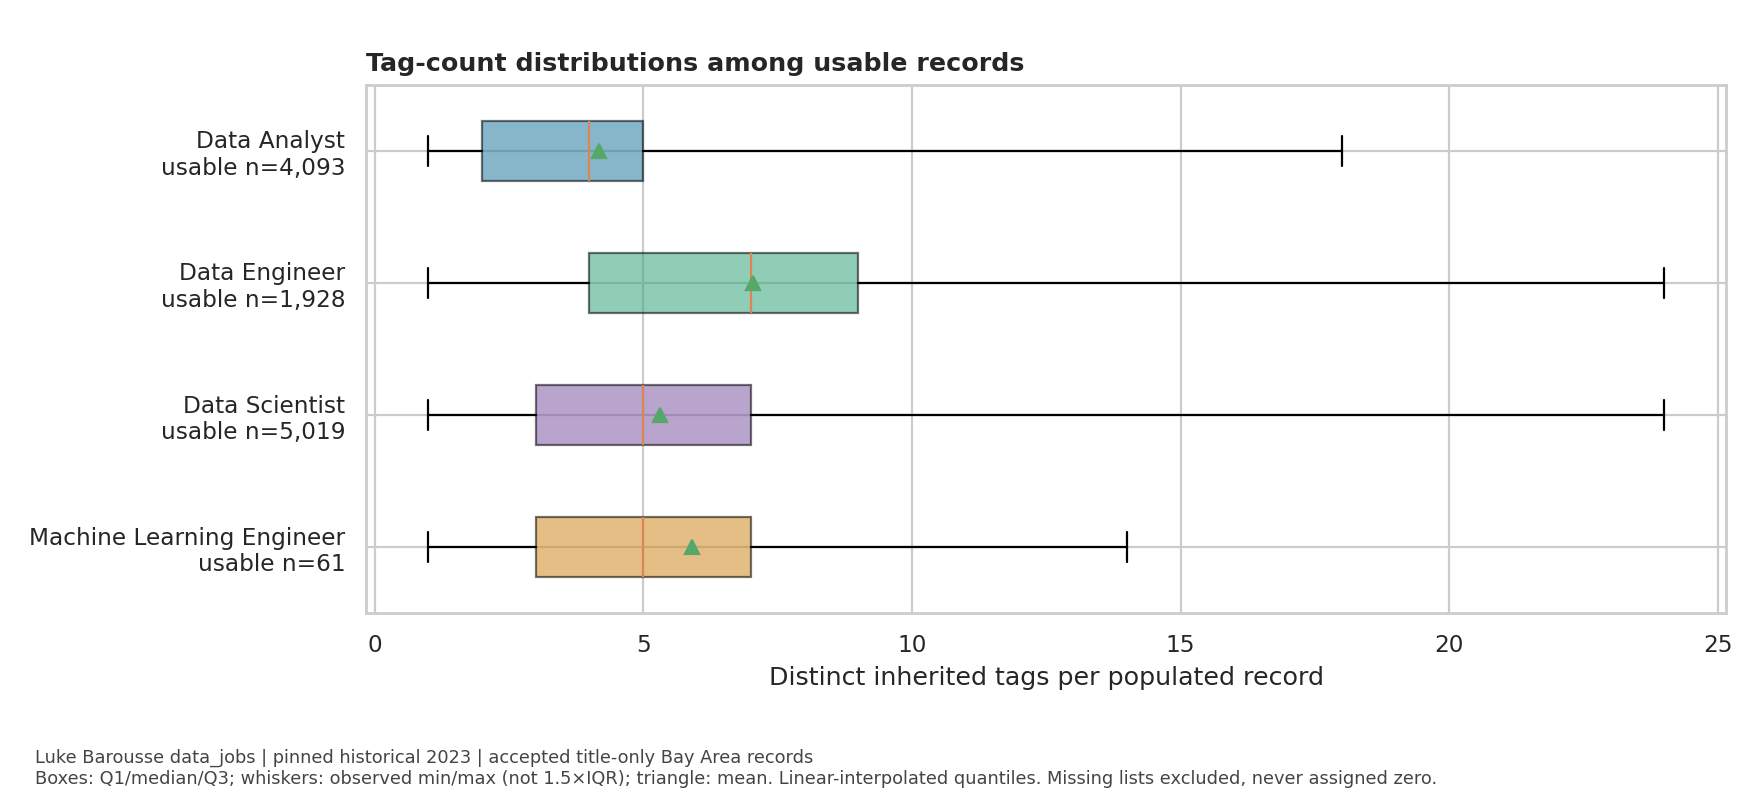

In [3]:
stats=tables['skill_count_summary'].copy()
stats['iqr_tags']=stats.q3_tags-stats.q1_tags
display(stats)
display(Image(filename=str(ROOT/'reports/figures/phase4_tag_count_distribution.png')))

## 3. Percentage-point contrasts
Illustrative exploratory examples: Python in DS vs DE, SQL in DA vs DE, Tableau in DA vs DS. Compare rates among usable lists with their own denominators. Seniority/employer/source mix is not controlled. A rate difference is not a causal effect or relative percent increase.

In [4]:
contrasts=pd.DataFrame(descriptive_comparisons(tables['skill_by_role']))
display(contrasts)
assert not {'p_value','confidence_interval'}.intersection(contrasts.columns)

,skill,first_role,second_role,first_usable_n,second_usable_n,first_tagged_n,second_tagged_n,first_pct,second_pct,difference_pp,all_record_difference_lower_pp,all_record_difference_upper_pp,comparison_allowed
0,python,Data Scientist,Data Engineer,5019,1928,4362,1461,86.909743,75.778008,11.131735,-0.525281,16.680072,True
1,sql,Data Analyst,Data Engineer,4093,1928,2879,1334,70.339604,69.190871,1.148733,-11.191842,9.307394,True
2,tableau,Data Analyst,Data Scientist,4093,5019,1898,1048,46.371854,20.880654,25.491201,8.970870,36.159490,True


## 4. Logical missing-data bounds
For each role, let n be all accepted records, u the usable lists and m the observed tagged records. The all-record tag rate could range from 100m/n to 100(m+n−u)/n if only missing-list content changes. No records are imputed. These are not confidence intervals or bounds on true requirements/extraction errors. Difference bounds subtract the second role’s upper/lower bound from the first role’s lower/upper bound.

,role,skill,tagged_records,usable_tag_records,role_records,usable_tag_pct,all_record_lower_pct,all_record_upper_pct
125,Data Analyst,python,1853,4093,4829,45.272416,38.372334,53.613585
157,Data Analyst,sql,2879,4093,4829,70.339604,59.618969,74.860220
166,Data Analyst,tableau,1898,4093,4829,46.371854,39.304204,54.545455
320,Data Engineer,python,1461,1928,2035,75.778008,71.793612,77.051597
352,Data Engineer,sql,1334,1928,2035,69.190871,65.552826,70.810811
361,Data Engineer,tableau,361,1928,2035,18.724066,17.739558,22.997543
515,Data Scientist,python,4362,5019,5700,86.909743,76.526316,88.473684
547,Data Scientist,sql,3283,5019,5700,65.411437,57.596491,69.543860
556,Data Scientist,tableau,1048,5019,5700,20.880654,18.385965,30.333333
710,Machine Learning Engineer,python,43,61,67,70.491803,64.179104,73.134328


,skill,first_role,second_role,difference_pp,all_record_difference_lower_pp,all_record_difference_upper_pp
0,python,Data Scientist,Data Engineer,11.131735,-0.525281,16.680072
1,sql,Data Analyst,Data Engineer,1.148733,-11.191842,9.307394
2,tableau,Data Analyst,Data Scientist,25.491201,8.970870,36.159490


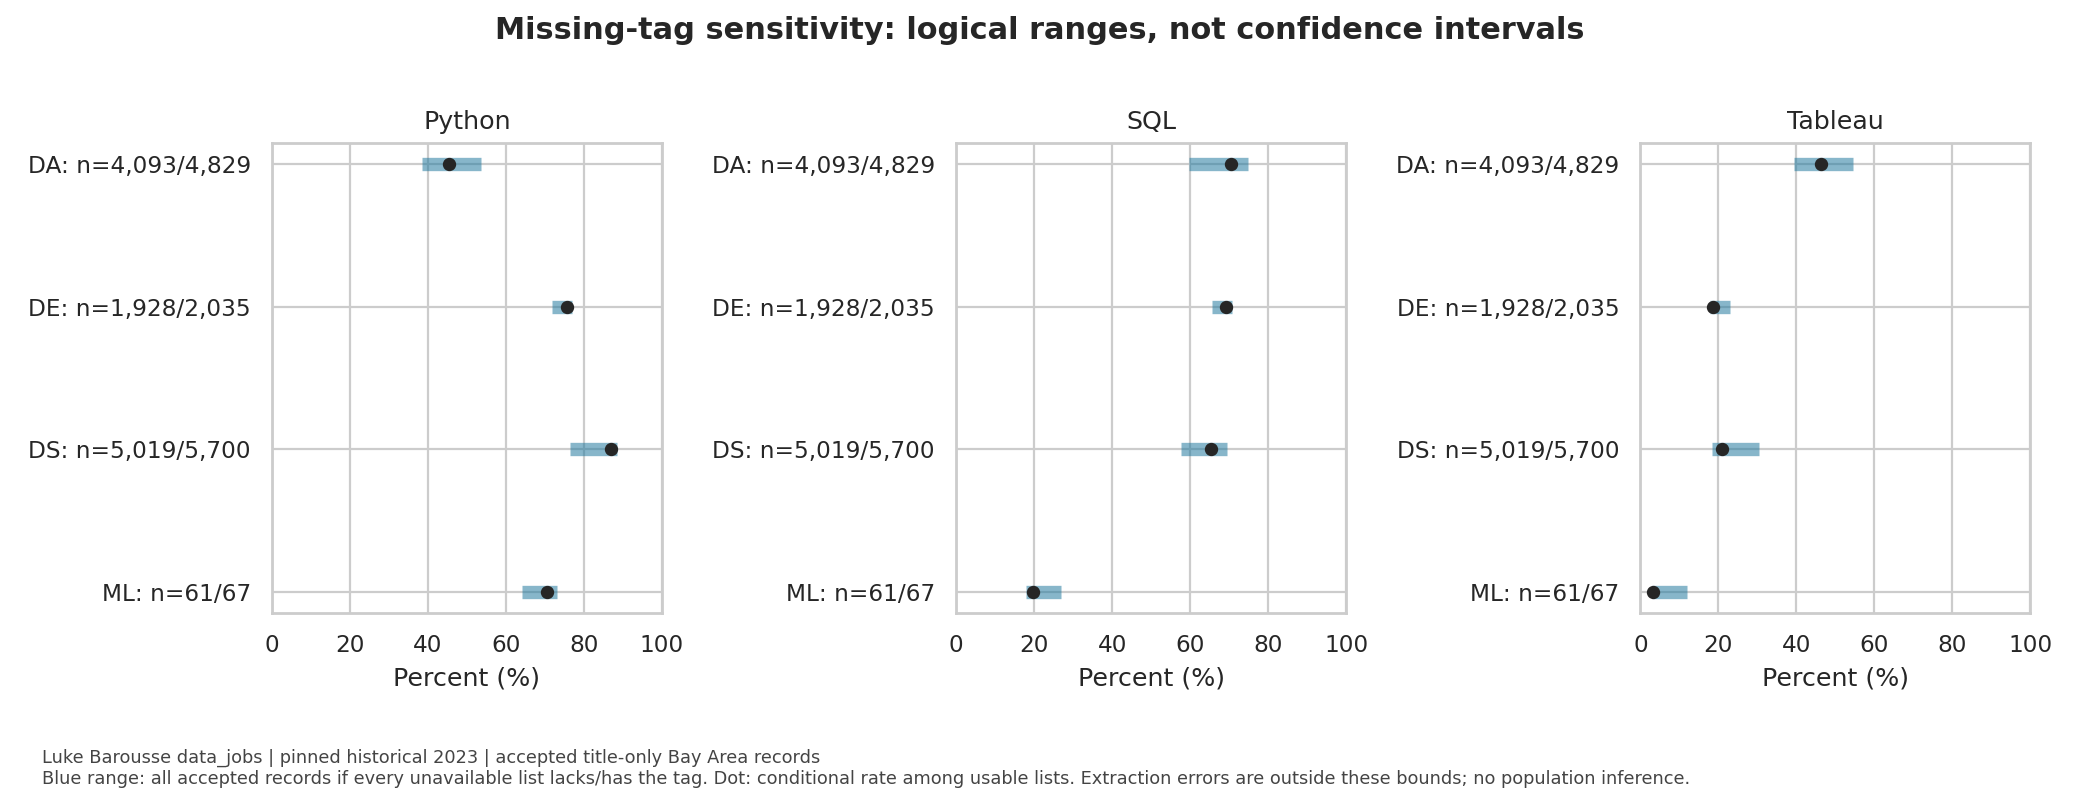

In [5]:
selected=tables['skill_by_role'].query("skill in ['python','sql','tableau']")
display(selected[['role','skill','tagged_records','usable_tag_records','role_records','usable_tag_pct','all_record_lower_pct','all_record_upper_pct']])
display(contrasts[['skill','first_role','second_role','difference_pp','all_record_difference_lower_pp','all_record_difference_upper_pp']])
display(Image(filename=str(ROOT/'reports/figures/phase4_missingness_sensitivity.png')))

## 5. Interpretation and stopping point
Non-random source coverage, repeated employers/reposts, conservative classification and missing descriptions prevent population inference. The n=10 rule is a reporting policy, not a guarantee of stability. Keep small groups visible; do not reinterpret unknown seniority as entry level. Salary comparisons, trends and arrangements stay disabled. Phase 5 is unstarted.

In [6]:
print('Source revision:',phase3['revision'])
print('Database SHA-256:',database_hash)
print('SQL/pandas tables reconciled:',len(checked))
print('No source, cleaning rule or schema changes; no new job data; no publishing.')

Source revision: ed776e5a0a8c40ea9d5efbd800772ae52e140f3e
Database SHA-256: d7a51a0b929d8f6f5746f35741bb312af781b2cc64e41a747ef59639ebc646cf
SQL/pandas tables reconciled: 9
No source, cleaning rule or schema changes; no new job data; no publishing.
